In [1]:
import os
#import argparse
#parser=argparse.ArgumentParser(description='trim video into short piece')
#parser.add_argument('-i','--input_path',help='path to the video as a string: eg. C:/Users/../, apostrophe not shown',type=str,default='Z:/DATA/experiment_trackball_Optomotor')
#parser.add_argument('-n','--exp_name',help='the stimulus name of the experiment: eg. xxx, apostrophe not shown',type=str,default='gratings')
#parser.add_argument('-d','--exp_date',help='the date of the experiment',type=list,default=['220712','220714'])
#args= parser.parse_args()
#def create_data_list(input_path, exp_name, exp_date):
data_list=[]
input_path = 'Z:/DATA/experiment_trackball_Optomotor'
dataset=os.listdir(input_path)
#exp_date=['220813','220811','220814']
exp_date=['221015','221016']
exp_name='sweeploom'
for locust in dataset:
    locust_directory=input_path + '/' + locust
    file_list = os.listdir(locust_directory)
    for thisDate in file_list:
        if thisDate in exp_date:
            experiment_directory=locust_directory + '/' + thisDate
            experiment_list=os.listdir(experiment_directory)
            for thisExperiment in experiment_list:
                if thisExperiment in exp_name:
                    data_list.append(experiment_directory + '/' + exp_name)
#    return data_list

#if __name__ == '__main__':
#    create_data_list(args.input_path,args.exp_name,args.exp_date)

In [282]:
##The meta information of the stimulus is now included in each cell when the stimulus is delivered
##They are saved as stim_variable object.
##For gratings: it only includs temporal frequency at the moment 2022 sep 6th
##For sweeploom: it includs the initial and ending size; initial and ending position, by this order 
##For sweeploom: it includs stimid, size, Colour1, numDots1, Contrast1, VelX1, Coherence1 by this order 
import os, fnmatch
import pandas as pd
import numpy as np
import re
def generate_curated_database(myList = [], *args):
    overwrite_file=True
    save_file=True
    #csv_pattern='trial_*.csv'
    dat_pattern='*.dat'    
    track_ball_radius=40
    frame_rate=144
    #stim_duration = 25 # in sec
    #grey_duration = 5
    for thisDir in myList:
        # list up the files in the dir
        file = os.listdir(thisDir)
        # look for files that matches the pattern
        dat_file= fnmatch.filter(file, dat_pattern)
        dat_file_directory= os.path.join(thisDir ,dat_file[0])

   
        ## load dat file
    
        raw_data = pd.read_table(dat_file_directory, sep="\s+")
        ## fictrac title is here 'frame counter', 'delta rotation vector cam x', 'delta rotation vector cam y', \
        ##'delta rotation vector cam z', 'delta rotation error score', 'delta rotation vector lab x', \
        ##'delta rotation vector lab y', 'delta rotation vector lab z', 'absolute rotation vector cam x',\
        ##'absolute rotation vector cam y', 'absolute rotation vector cam z', \
        ##'absolute rotation vector lab x', 'absolute rotation vector lab y', \
        ##'absolute rotation vector lab z', 'intergrated x position','intergrated y position', \
        ##'intergrated animal heading', 'animal movement direction', 'animal movement speed', \
        ##'intergrated forward motion','intergrated side motion', 'timestamp', 'sequence counter','delta timestamp', 'alt. timestamp']

        ## drop some column
        raw_data.drop(raw_data.columns[[0,1,2,3,4,8,9,10,16,17,19,20,21,22,23]], axis=1, inplace=True)
        raw_data.columns=['delta rotation vector lab x', 'delta rotation vector lab y', 'delta rotation vector lab z',                       'absolute rotation vector lab x', 'absolute rotation vector lab y', 'absolute rotation vector lab z',                       'intergrated x position','intergrated y position','instant speed','timestamp']
        ## cleaning , and change the data from object to float
        raw_data.iloc[:, :]=raw_data.iloc[:, :].replace({',': ''}, regex= True)
        for ind in range(0, raw_data.shape[1]):
            raw_data.iloc[:, ind]=pd.to_numeric(raw_data.iloc[:, ind]).astype('float32')
        
        ## adjust the unit of the x, y position
        raw_data.iloc[:, 6]=raw_data.iloc[:, 6]*track_ball_radius
        raw_data.iloc[:, 7]=raw_data.iloc[:, 7]*track_ball_radius
        raw_data.iloc[:, 8]=raw_data.iloc[:, 8]*track_ball_radius*frame_rate
        ## adjust the unit of the z vector based on the target frame rate of fictrac
        raw_data.iloc[:, 2]=raw_data.iloc[:, 2]
  
        ### save the curated_database
        if save_file==True:
            database_name='database_curated.pickle'
            database_directory= os.path.join(thisDir,database_name)
            if (overwrite_file ==False) and (os.path.isfile == True):
                continue
            else:
                raw_data.to_pickle(database_directory)

In [2]:
data_list

['Z:/DATA/experiment_trackball_Optomotor/L22116/221015/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22117/221015/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22118/221015/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22119/221015/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22120/221015/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22121/221015/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22122/221016/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22123/221016/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22124/221016/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22125/221016/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22126/221016/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22127/221016/sweeploom',
 'Z:/DATA/experiment_trackball_Optomotor/L22128/221016/sweeploom']

In [284]:
generate_curated_database(data_list)

In [3]:
import os, fnmatch
import pandas as pd
import numpy as np
import re
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
csv_pattern='trial_*.csv'
database_pattern='*.pickle'
exp_name='sweeploom'
frame_rate=144
stim_duration=3
grey_duration=1
#analysis_window=frame_rate*(stim_duration+grey_duration)
analysis_window=[-2, 5]
window_length=analysis_window[1]-analysis_window[0]
stim_type=["c2b_f_sloom","c2b_s_sloom","c2f_f_sloom","c2f_s_sloom","c2c_f_loom","c2c_s_loom"]

In [27]:
sg_filering= True
analyse_every_trial = False
plotting_trajectory = False
closed_loop_experiment = False
plotting_event_related_trajectory = True
save_fig = True
stim_of_interest=stim_type[4]

In [212]:
thisDir=data_list[12]

In [197]:
thisDir

'Z:/DATA/experiment_trackball_Optomotor/L22124/221016/sweeploom'

In [213]:
file = os.listdir(thisDir)
file_name= fnmatch.filter(file, database_pattern)
database= os.path.join(thisDir,file_name[0])
df=pd.read_pickle(database)
if sg_filering == True:
    x_all = savgol_filter(df.loc[:, ['intergrated x position']], 71, 3, axis=0)
    y_all = savgol_filter(df.loc[:, ['intergrated y position']], 71, 3, axis=0)
    instant_v=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
    runmean_v=df['instant speed'].rolling(10).mean().values
    #vx=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
    #vz=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
else:
    x_all = df.loc[:, ['intergrated x position']]
    y_all = df.loc[:, ['intergrated y position']]

if plotting_trajectory == True:
    plt.plot(x_all, y_all,c=np.arange(len(y_all)), marker='.', alpha=0.5)
    plt.show()   

csv_file= fnmatch.filter(file, csv_pattern)
csv_file_directory= os.path.join(thisDir ,csv_file[0])    
stim_info = pd.read_csv(csv_file_directory)
stim_info=stim_info.reset_index()
stim_variable=[]
stimulus_timestamp=[]

if exp_name == 'gratings':
    for row in range(0, len(stim_info)):
    #delete the bracket in current speed and save it as integer in new list
        stim_variable.append(int(stim_info.loc[row, 'Frame'].replace('(', '')))
    # combine the last two values into the timestamp (were divided into 2 columns cause german computer
    # used comma as decimal seperator and save timestamp as float in new file
        if isinstance(stim_info.loc[row, 'Value'], float):
            timestamp = stim_info.loc[row, 'Timestamp']
        else:
            timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
        stimulus_timestamp.append(float(timestamp.replace(')', '')))
    stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))

elif exp_name == 'sweeploom':
    for row in range(0, len(stim_info)):
        stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,3].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,5].split("=",1)[1]))
        #stim_variable.append(int(re.split(r'=|}',stim_info.iloc[row,5])[1]))
        if isinstance(stim_info.loc[row, 'Value'], float):
            timestamp = stim_info.loc[row, 'Timestamp']
        else:
            timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
        stimulus_timestamp.append(float(timestamp.replace(')', '')))
    stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
    #some bugs in the bonsai workflow. Needs to remove the first timestamp and the last row of stim variable here
    if closed_loop_experiment == True:
        stimulus_timestamp.pop(0)
        stim_variable=np.delete(stim_variable, -1, axis=0)
elif exp_name == 'dots':
    for row in range(0, len(stim_info)):
        stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,5].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,11].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,13].split("=",1)[1]))
        stim_variable.append(int(stim_info.iloc[row,17].split("=",1)[1]))
        if isinstance(stim_info.loc[row, 'Value'], float):
            timestamp = stim_info.loc[row, 'Timestamp']
        else:
            timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
        stimulus_timestamp.append(float(timestamp.replace(')', '')))
    stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
else:
    warnings.warn('stimulus paradigm can not be recognised')

stim_df=pd.DataFrame(stim_variable)    

    # compare the timestamp between event file and dat file
data_timestamp=df.loc[:, 'timestamp']
stimulus_timestamp_b=np.tile(stimulus_timestamp,(len(data_timestamp),1))
data_timestamp_b=np.tile(data_timestamp,(len(stimulus_timestamp),1))
timestamp_diff= data_timestamp_b > np.transpose(stimulus_timestamp_b)
stim_onset= np.where(np.roll(timestamp_diff,1,axis=1)!=timestamp_diff)[1][1::2]
stim_df["stim_onset"]=stim_onset

filters=[(stim_df.iloc[:,0]==1) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]),
(stim_df.iloc[:,0]==8) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]),
(stim_df.iloc[:,0]==1) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]),
(stim_df.iloc[:,0]==8) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]),
(stim_df.iloc[:,0]==1) & (stim_df.iloc[:,2] == stim_df.iloc[:,3]),
(stim_df.iloc[:,0]==8) & (stim_df.iloc[:,2] == stim_df.iloc[:,3])]

### add new column here to store event info
#         raw_data['frame_rate']=frame_rate
#         if isinstance(frame_rate, int):
#             raw_data['frame_rate']=raw_data['frame_rate'].astype('int16')  
#         elif isinstance(frame_rate, int):
#             raw_data['frame_rate']=raw_data['frame_rate'].astype('float16')

stim_df["stim_type"]=np.select(filters, stim_type)

In [224]:
if analyse_every_trial==True:
    stim_to_analyse=stim_df.loc[:,'stim_onset']
    stim_name_list=np.array(stim_df["stim_type"])
#elif: 'myVar' in locals():
#stim_type=["m2b_f_sloom","m2b_s_sloom","m2f_f_sloom","m2f_s_sloom","m2m_f_loom","m2m_s_loom"]
else:
    #stim_to_analyse=stim_df.loc[np.where(stim_df.loc[:,'stim_type']==stim_of_interest),"stim_onset"]
    #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "f2b_l_sweep") | (stim_df.loc[:,'stim_type']== "f2b_r_sweep")),"stim_onset"]
    #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "b2f_l_sweep") | (stim_df.loc[:,'stim_type']== "b2f_r_sweep")),"stim_onset"]
    #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "b2f_l_sloom") | (stim_df.loc[:,'stim_type']== "b2f_r_sloom")),"stim_onset"]
    #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "c2b_f_sloom") | (stim_df.loc[:,'stim_type']== "m2b_s_sloom")),"stim_onset"]
    # stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "c2b_f_sloom")),"stim_onset"]
    stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "c2c_s_loom")),"stim_onset"]
    stim_name_list=stim_df.loc[stim_to_analyse.index,'stim_type'].values
if len(stim_to_analyse) ==0:
    print('no_required_stim_type')
    #continue

# cum_travel_distance=np.cumsum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
# init_time=abs(analysis_window[0])
# end_time=abs(analysis_window[0])+stim_duration
# travel_distance_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]
# travel_distance_post_stim=cum_travel_distance[:,end_time*frame_rate,0]
# travel_distance_during_stim=travel_distance_post_stim-travel_distance_prior_stim
# normalise_travel_distance=np.divide(travel_distance_post_stim,travel_distance_prior_stim)       
# travel_distance_prior_stim_all.append(travel_distance_prior_stim)
# travel_distance_tbt.append(cum_travel_distance)
# mean_travel_distance_during_stim.append(np.mean(travel_distance_during_stim))
# mean_normalised_distance_during_stim.append(np.mean(normalise_travel_distance))


grey_onset=stim_to_analyse+np.ones(len(stim_to_analyse),dtype=int)*analysis_window[0]*frame_rate
analysie_window_tile=np.tile(np.arange(window_length*frame_rate),(len(grey_onset),1))
index_points=np.array(grey_onset).reshape(len(grey_onset),1)+analysie_window_tile
x=x_all[index_points]
y=y_all[index_points]
x_dif=np.diff(x,axis=1)
y_dif=np.diff(y,axis=1)
travel_distance_fbf=np.sqrt(np.add(np.square(x_dif), np.square(y_dif)))
velocity=travel_distance_fbf*frame_rate
cum_travel_distance=np.cumsum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
init_time=abs(analysis_window[0])
end_time=abs(analysis_window[0])+stim_duration
travel_distance_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]
travel_distance_post_stim=cum_travel_distance[:,end_time*frame_rate,0]
mean_travel_distance_post_stim=np.mean(travel_distance_post_stim)
travel_distance_during_stim=travel_distance_post_stim-travel_distance_prior_stim
normalise_travel_distance=np.divide(travel_distance_post_stim,travel_distance_prior_stim)  
mean_normalise_travel_distance=np.mean(normalise_travel_distance)

travel_distance_1sec_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]-cum_travel_distance[:,(init_time-1)*frame_rate,0]
running_trial=travel_distance_1sec_prior_stim>5
running_velocity=velocity[running_trial,:]
travel_distance_1sec_post_stim=cum_travel_distance[running_trial,(init_time+1)*frame_rate,0]-cum_travel_distance[running_trial,init_time*frame_rate,0]
velocity_type1=running_velocity[travel_distance_1sec_post_stim>5,:]
velocity_type2=running_velocity[travel_distance_1sec_post_stim<5,:]


#travel_distance=np.sum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
vx=df.loc[:, ['delta rotation vector lab x']].values
velocity_x=vx[index_points]
vz=df.loc[:, ['delta rotation vector lab z']].values
velocity_z=vz[index_points]
#instant_v=df.loc[:, ['instant speed']].values
##this is a small test for how to quantify velocity
#velocity=instant_v[index_points]
velocity_rolling=runmean_v[index_points]
tp=np.linspace(0,window_length,velocity.shape[1])
tp_tile=np.tile(tp,(velocity.shape[0],1))

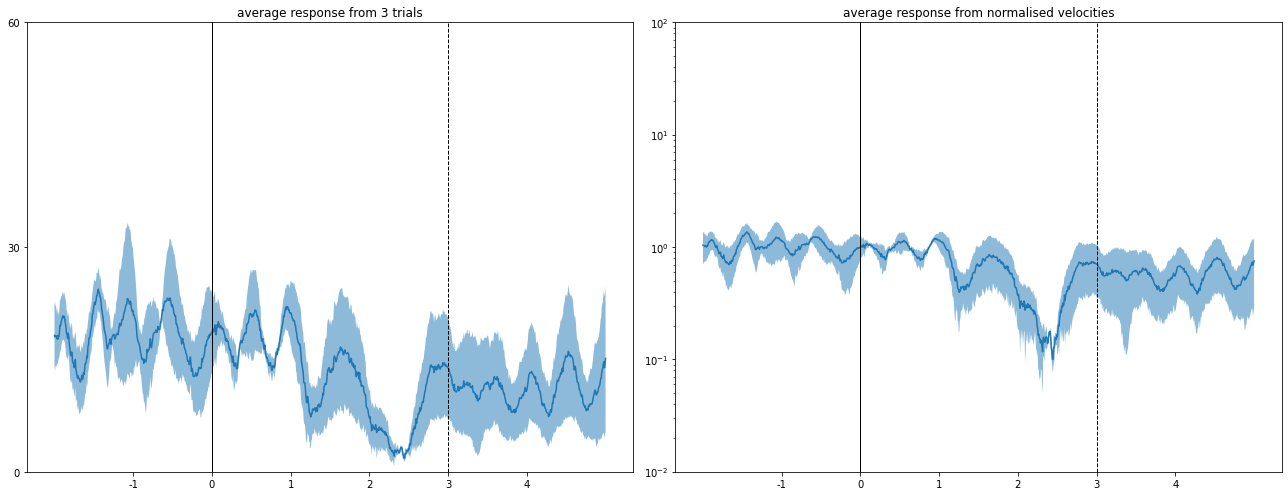

In [225]:
mean_velocity=np.mean(velocity_type1[:,:,0], axis=0)
sem_velocity=np.std(velocity_type1[:,:,0], axis=0, ddof=1) / np.sqrt(velocity_type1[:,:,0].shape[0])
v_base=np.median(velocity_type1[:,init_time*frame_rate:(init_time+1)*frame_rate,0],axis=1)
v_interest=velocity_type1[:,:,0]
normalise_v=v_interest.T/v_base
mean_velocity_norm=np.mean(normalise_v.T, axis=0)
sem_velocity_norm=np.std(normalise_v.T, axis=0, ddof=1) / np.sqrt(normalise_v.T.shape[0])
mean_tile=np.mean(tp_tile, axis=0)
v_add_sem = mean_velocity + sem_velocity
v_min_sem = mean_velocity - sem_velocity
v_add_sem_norm = mean_velocity_norm + sem_velocity_norm
v_min_sem_norm = mean_velocity_norm - sem_velocity_norm
fig, (ax,ax2)= plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
# ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
ax.plot(mean_tile,mean_velocity)
ax.fill_between(mean_tile,v_add_sem,v_min_sem, alpha=0.5, linewidth=0)
ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
ax.set_ylim(0, 60)
ax.set_yticks([0,30,60])
ax.set_yticklabels(['0','30','60'])
ax.set_xticks([1,2,3,4,5,6])
ax.set_xticklabels(['-1','0','1','2','3','4'])
plot_title=f'average response from {velocity_type1[:,:,0].shape[0]} trials'
ax.set_title(plot_title)

ax2.plot(mean_tile,mean_velocity_norm)
ax2.fill_between(mean_tile,v_add_sem_norm,v_min_sem_norm, alpha=0.5, linewidth=0)
ax2.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
ax2.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
ax2.set_ylim(0.01, 100)
ax2.set_yscale('log')
ax2.set_xticks([1,2,3,4,5,6])
ax2.set_xticklabels(['-1','0','1','2','3','4'])
plot_title=f'average response from normalised velocities'
ax2.set_title(plot_title)
plot_file=f'stim_{stim_name_list[0]}_velocity_run_trials_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
if save_fig == True:
    plt.savefig(thisDir+plot_file)

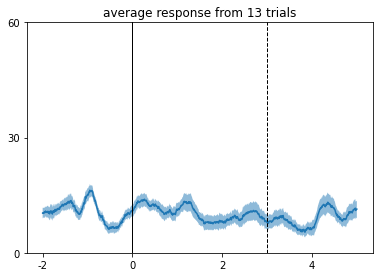

In [74]:
mean_velocity=np.mean(velocity_type1[:,:,0], axis=0)
sem_velocity=np.std(velocity_type1[:,:,0], axis=0, ddof=1) / np.sqrt(velocity_type1[:,:,0].shape[0])
# elif plotting_stationary_trial_average==True and velocity[travel_distance_prior_stim<5,:].shape[0] > 0:
#     mean_velocity=np.mean(velocity[travel_distance_prior_stim<5,:], axis=0)
#     sem_velocity=np.std(velocity[travel_distance_prior_stim<5,:], axis=0, ddof=1) / np.sqrt(velocity[travel_distance_prior_stim<5,:].shape[0])
#     plot_file=f'stim_{stim_name_list[0]}_mean_velocity_stationary_trials_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
# fig, (ax1,ax2)= plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
mean_tile=np.mean(tp_tile, axis=0)
v_add_sem = mean_velocity + sem_velocity
v_min_sem = mean_velocity - sem_velocity
fig = plt.figure()
ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
ax.plot(mean_tile,mean_velocity)
ax.fill_between(mean_tile,v_add_sem,v_min_sem, alpha=0.5, linewidth=0)
ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
plt.ylim(0, 60)
ax.set_yticks([0,30,60])
ax.set_yticklabels(['0','30','60'])
ax.set_xticks([1,2,3,4])
ax.set_xticklabels(['-1','0','1','2'])
plot_title=f'average response from {velocity_type1[:,:,0].shape[0]} trials'
ax.set_title(plot_title)
plot_file=f'stim_{stim_name_list[0]}_mean_velocity_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
if save_fig == True:
    plt.savefig(thisDir+plot_file)

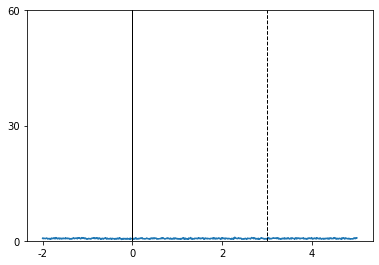

In [242]:
##this cell contains function to plot average speed

plotting_all_trials_average=False
plotting_running_trial_average=False
plotting_stationary_trial_average=True
##this is a good cell to plot average response
if plotting_all_trials_average==True:
    mean_velocity=np.mean(velocity, axis=0)
    sem_velocity=np.std(velocity, axis=0, ddof=1) / np.sqrt(velocity.shape[0])
    plot_file=f'stim_{stim_name_list[0]}_mean_velocity_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
elif plotting_running_trial_average==True and velocity[travel_distance_prior_stim>5,:].shape[0] > 0:
    mean_velocity=np.mean(velocity[travel_distance_prior_stim>5,:], axis=0)
    sem_velocity=np.std(velocity[travel_distance_prior_stim>5,:], axis=0, ddof=1) / np.sqrt(velocity[travel_distance_prior_stim>5,:].shape[0])
    plot_file=f'stim_{stim_name_list[0]}_mean_velocity_run_trials_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
elif plotting_stationary_trial_average==True and velocity[travel_distance_prior_stim<5,:].shape[0] > 0:
    mean_velocity=np.mean(velocity[travel_distance_prior_stim<5,:], axis=0)
    sem_velocity=np.std(velocity[travel_distance_prior_stim<5,:], axis=0, ddof=1) / np.sqrt(velocity[travel_distance_prior_stim<5,:].shape[0])
    plot_file=f'stim_{stim_name_list[0]}_mean_velocity_stationary_trials_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
else:
    print('ahh oh forget specify what to analyse or check if there is enough trial')

mean_tile=np.mean(tp_tile, axis=0)
v_add_sem = mean_velocity + sem_velocity
v_min_sem = mean_velocity - sem_velocity
fig = plt.figure()
ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
ax.plot(mean_tile,mean_velocity)
ax.fill_between(mean_tile,v_add_sem[:,0],v_min_sem[:,0], alpha=0.5, linewidth=0)
ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
plt.ylim(0, 60)
ax.set_yticks([0,30,60])
ax.set_yticklabels(['0','30','60'])
ax.set_xticks([0,2,4,6])
ax.set_xticklabels(['-2','0','2','4'])
plt.savefig(thisDir+plot_file)

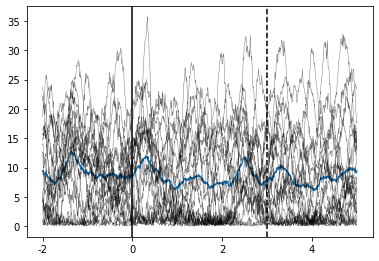

In [81]:
##this is a good cell to plot average response plue tbt response
mean_velocity=np.mean(velocity, axis=0)
sem_velocity=np.std(velocity, axis=0, ddof=1) / np.sqrt(velocity.shape[0])
mean_tile=np.mean(tp_tile, axis=0)
v_add_sem = mean_velocity + sem_velocity
v_min_sem = mean_velocity - sem_velocity
fig = plt.figure()
ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
ax.plot(mean_tile,mean_velocity)
for thisRow in range(0,index_points.shape[0]):
    ax.plot(mean_tile,velocity[thisRow,:],'k',alpha=0.5,lw=0.5)
#ax.fill_between(mean_tile,v_add_sem[:,0],v_min_sem[:,0], alpha=0.5, linewidth=0)
ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Second Line')
ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Second Line')
#plt.ylim(0, 0.05)
#ax.set_yticks([0,0.025,0.05])
#ax.set_yticklabels(['0','0.025','0.05'])
ax.set_xticks([0,2,4,6])
ax.set_xticklabels(['-2','0','2','4'])
plot_file=f'stim_{stim_name_list[0]}_mean_velocity_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
#plt.savefig(thisDir+plot_file)

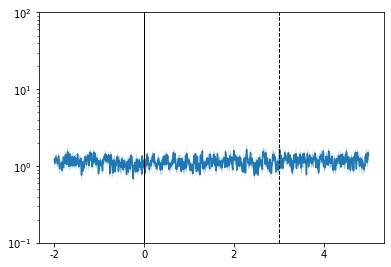

In [244]:
##this cell contains function to plot average normalise speed

plotting_all_trials_average=False
plotting_running_trial_average=False
plotting_stationary_trial_average=True
##this is a good cell to plot average response

if plotting_all_trials_average==True:
    mean_velocity=np.mean(velocity, axis=0)
    sem_velocity=np.std(velocity, axis=0, ddof=1) / np.sqrt(velocity.shape[0])
    plot_file=f'stim_{stim_name_list[0]}_normalised_velocity_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
elif plotting_running_trial_average==True and velocity[travel_distance_prior_stim>5,:].shape[0] > 0:
    v_base=np.median(velocity[travel_distance_prior_stim>5,0:init_time*frame_rate],axis=1)
    v_interest=velocity[travel_distance_prior_stim>5,:,0]
    normalise_v=v_interest.T/v_base[:,0]
    mean_velocity=np.mean(normalise_v.T, axis=0)
    sem_velocity=np.std(normalise_v.T, axis=0, ddof=1) / np.sqrt(normalise_v.T.shape[0])
    plot_file=f'stim_{stim_name_list[0]}_normalised_velocity_run_trials_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
elif plotting_stationary_trial_average==True and velocity[travel_distance_prior_stim<5,:].shape[0] > 0:
    v_base=np.median(velocity[travel_distance_prior_stim<5,0:init_time*frame_rate],axis=1)
    v_interest=velocity[travel_distance_prior_stim<5,:,0]
    normalise_v=v_interest.T/v_base[:,0]
    mean_velocity=np.mean(normalise_v.T, axis=0)
    sem_velocity=np.std(normalise_v.T, axis=0, ddof=1) / np.sqrt(normalise_v.T.shape[0])
    #mean_velocity=np.mean(velocity[travel_distance_prior_stim<5,:], axis=0)
    #sem_velocity=np.std(velocity[travel_distance_prior_stim<5,:], axis=0, ddof=1) / np.sqrt(velocity[travel_distance_prior_stim<5,:].shape[0])
    plot_file=f'stim_{stim_name_list[0]}_normalised_velocity_stationary_trials_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
else:
    print('ahh oh forget specify what to analyse or check if there is enough trial')

mean_tile=np.mean(tp_tile, axis=0)
v_add_sem = mean_velocity + sem_velocity
v_min_sem = mean_velocity - sem_velocity

fig = plt.figure()
ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
ax.plot(mean_tile,mean_velocity)
ax.fill_between(mean_tile,v_add_sem,v_min_sem, alpha=0.5, linewidth=0)
ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
plt.ylim(0.1, 100)
#ax.set_yticks([0,10,20])
#ax.set_yticklabels(['0','10','20'])
ax.set_yscale('log')
ax.set_xticks([0,2,4,6])
ax.set_xticklabels(['-2','0','2','4'])
plt.savefig(thisDir+plot_file)

In [ ]:
##this is a good cell to plot average response plue tbt response
mean_velocity=np.mean(velocity, axis=0)
sem_velocity=np.std(velocity, axis=0, ddof=1) / np.sqrt(velocity.shape[0])
mean_tile=np.mean(tp_tile, axis=0)
v_add_sem = mean_velocity + sem_velocity
v_min_sem = mean_velocity - sem_velocity
fig = plt.figure()
ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
ax.plot(mean_tile,mean_velocity)
for thisRow in range(0,index_points.shape[0]):
    ax.plot(mean_tile,velocity[thisRow,:],'k',alpha=0.5,lw=0.5)
#ax.fill_between(mean_tile,v_add_sem[:,0],v_min_sem[:,0], alpha=0.5, linewidth=0)
ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Second Line')
ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Second Line')
#plt.ylim(0, 0.05)
#ax.set_yticks([0,0.025,0.05])
#ax.set_yticklabels(['0','0.025','0.05'])
ax.set_xticks([0,2,4,6])
ax.set_xticklabels(['-2','0','2','4'])
plot_file=f'stim_{stim_name_list[0]}_mean_velocity_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
#plt.savefig(thisDir+plot_file)

In [ ]:
##this is a cell to save individual trajectory
for ind in range(0,index_points.shape[0]):
    fig = plt.figure()
    plt.scatter(x[ind,:],y[ind,:],c=np.arange(len(x[ind,:])), marker='.', alpha=0.5)
    plt.scatter(x[ind,abs(analysis_window[0]*frame_rate)],y[ind,abs(analysis_window[0]*frame_rate)],s=200,c='k', marker='*', alpha=0.5)
    plot_file=f'stim_{stim_name_list[ind]}{str(ind)}_trajectory_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
    plt.savefig(thisDir+plot_file)

In [ ]:
##this is a cell to save individual plot
analysis_window=[-2, 5]
for ind in range(0,index_points.shape[0]):
    fig = plt.figure()
    ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) 
    plt.plot(tp_tile[ind,:],velocity[ind,:])
    plt.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Onset')
    plt.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Offset')
    ax.set_yticks([0,50,100])
    ax.set_yticklabels(['0','50','100'])
    ax.set_xticks([0,2,4,6])
    ax.set_xticklabels(['-2','0','2','4'])
    plot_file=f'stim_{stim_name_list[ind]}{str(ind)}_velocity_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
    plt.savefig(thisDir+plot_file)

In [ ]:
##this uses subplot function to plot the trajectory
fig, axes = plt.subplots(1,index_points.shape[0],figsize=(30,4),squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.scatter(x[ind,:],y[ind,:],c=np.arange(len(x[ind,:])), marker='.', alpha=0.5)
    ax.scatter(x[ind,abs(analysis_window[0]*frame_rate)],y[ind,abs(analysis_window[0]*frame_rate)],s=200,c='k', marker='*', alpha=0.5)
    #ax.set_title(stim_name_list[col])
plot_file=f'stim_{stim_name_list[0]}_trajectory_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
plt.savefig(thisDir+plot_file)
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

In [ ]:
##this uses subplot function to plot the speed
fig, axes = plt.subplots(1,index_points.shape[0], figsize=(30,4), squeeze=False)
for ind, ax in zip(range(0,index_points.shape[1]),axes.reshape(-1)):
    ax.plot(tp_tile[ind,:],velocity[ind,:])
    ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Second Line')
    ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Second Line')
    #ax.set_title(stim_name_list[col])
plt.show()
print(thisDir)
print(stim_name_list)
print(travel_distance)

## when calculating something across stimulus types

In [278]:
distance_stim=[]
normalised_distance_stim=[]
stim_size=[]
travel_distance_prior_stim_all=[]
#analysis_window=[0,4]
#window_length=4
velocity_list=[]
#ax.hist(a, bins = [0, 25, 50, 75, 100])

for thisStim in stim_type:
    if analyse_every_trial==True:
        stim_to_analyse=stim_df.loc[:,'stim_onset']
        stim_name_list=np.array(stim_df["stim_type"])
    #elif: 'myVar' in locals():
    #stim_type=["m2b_f_sloom","m2b_s_sloom","m2f_f_sloom","m2f_s_sloom","m2m_f_loom","m2m_s_loom"]
    else:
        #stim_to_analyse=stim_df.loc[np.where(stim_df.loc[:,'stim_type']==stim_of_interest),"stim_onset"]
        #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "f2b_l_sweep") | (stim_df.loc[:,'stim_type']== "f2b_r_sweep")),"stim_onset"]
        #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "b2f_l_sweep") | (stim_df.loc[:,'stim_type']== "b2f_r_sweep")),"stim_onset"]
        #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "b2f_l_sloom") | (stim_df.loc[:,'stim_type']== "b2f_r_sloom")),"stim_onset"]
        #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "m2b_f_sloom") | (stim_df.loc[:,'stim_type']== "m2b_s_sloom")),"stim_onset"]
        stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== thisStim)),"stim_onset"]
        #stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== "m2m_s_loom")),"stim_onset"]
        stim_name_list=stim_df.loc[stim_to_analyse.index,'stim_type'].values
    if len(stim_to_analyse) ==0:
        print('no_required_stim_type')
        #continue

    grey_onset=stim_to_analyse+np.ones(len(stim_to_analyse),dtype=int)*analysis_window[0]*frame_rate
    analysie_window_tile=np.tile(np.arange(window_length*frame_rate),(len(grey_onset),1))
    index_points=np.array(grey_onset).reshape(len(grey_onset),1)+analysie_window_tile
    x=x_all[index_points]
    y=y_all[index_points]    
    x_dif=np.diff(x,axis=1)
    y_dif=np.diff(y,axis=1)
    travel_distance_fbf=np.sqrt(np.add(np.square(x_dif), np.square(y_dif)))
    velocity=travel_distance_fbf*frame_rate
    #velocity=instant_v[index_points]
    stim_size.append(velocity.shape[0])
    velocity_list.append(velocity[:,:,0])

    cum_travel_distance=np.cumsum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
    init_time=abs(analysis_window[0])
    end_time=abs(analysis_window[0])+stim_duration
    travel_distance_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]
    travel_distance_post_stim=cum_travel_distance[:,end_time*frame_rate,0]
    travel_distance_during_stim=travel_distance_post_stim-travel_distance_prior_stim
    normalise_travel_distance=np.divide(travel_distance_post_stim,travel_distance_prior_stim)       
    #fig, ax = plt.subplots(figsize =(10, 7))
    #ax.hist(travel_distance, bins=[0,5,10,15,20,25,30])
    #plt.ylim(0, 30)
    travel_distance_prior_stim_all.append(travel_distance_prior_stim)
    distance_stim.append(np.mean(travel_distance_during_stim))
    normalised_distance_stim.append(np.mean(normalise_travel_distance))

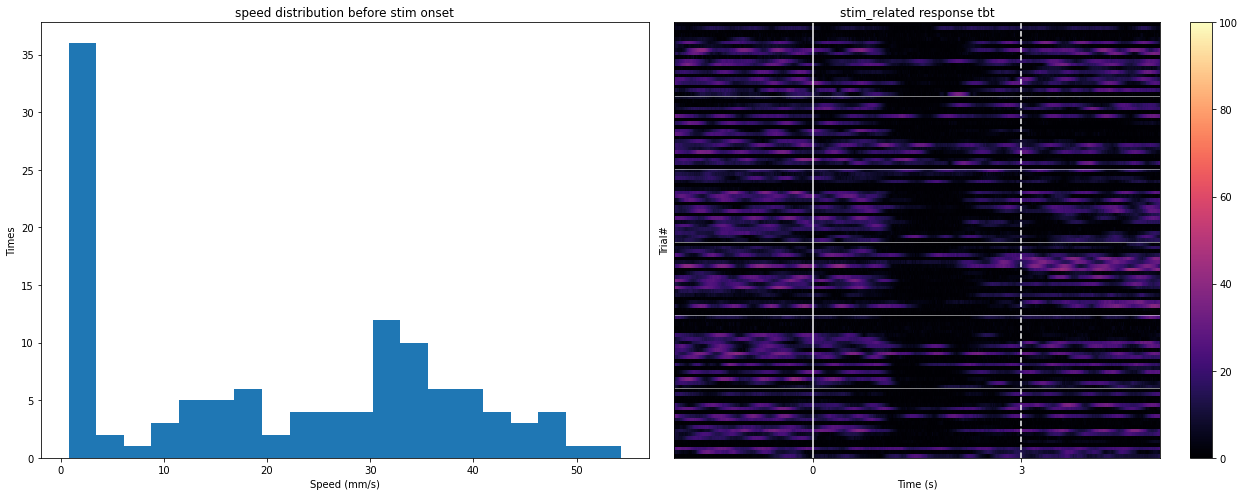

In [299]:
heatmap_xticks=[abs(analysis_window[0])*frame_rate, (stim_duration+abs(analysis_window[0]))*frame_rate]
cum_stim_size=np.cumsum(stim_size)
velocity_stim=np.vstack(velocity_list)
travel_distance_frequency=np.concatenate(travel_distance_prior_stim_all)
n_bins=20
fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
#travel_distance_prior_stim_all
ax1.hist(travel_distance_frequency, bins=n_bins)
ax1.set_xlabel('Speed (mm/s)')
ax1.set_ylabel('Times')
ax1.set_title('speed distribution before stim onset')
pcm=ax2.pcolormesh(velocity_stim, cmap = 'magma',vmin = 0, vmax =100)
fig.colorbar(pcm)
#ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
ax2.axvline(x=abs(analysis_window[0]*frame_rate), color='white', linestyle='-', label='Stimulus Starts')
ax2.axvline(x=(abs(analysis_window[0]*frame_rate)+stim_duration*frame_rate), color='white', linestyle='--', label='Stimulus Ends')
for ind in range(0,cum_stim_size.shape[0]):
    ax2.axhline(y=cum_stim_size[ind], color='white', linestyle='-', label='Stimulus Type',linewidth=0.5)
ax2.set_xticks([heatmap_xticks[0],heatmap_xticks[1]])
ax2.set_xticklabels(['0','3'])
ax2.set_yticks([])
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Trial#')
ax2.set_title('stim_related response tbt')
plot_file=f'stim_heatmap_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
#plt.savefig(thisDir+plot_file)

(array([36.,  2.,  1.,  3.,  5.,  5.,  6.,  2.,  4.,  4.,  4., 12., 10.,
         6.,  6.,  4.,  3.,  4.,  1.,  1.]),
 array([ 0.74934447,  3.4287887 ,  6.108233  ,  8.787678  , 11.467121  ,
        14.146565  , 16.82601   , 19.505455  , 22.184898  , 24.864344  ,
        27.543787  , 30.223232  , 32.902676  , 35.58212   , 38.261566  ,
        40.94101   , 43.620453  , 46.299896  , 48.979343  , 51.658787  ,
        54.33823   ], dtype=float32),
 <BarContainer object of 20 artists>)

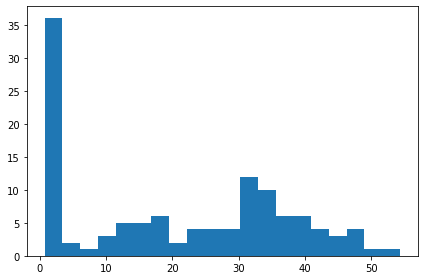

In [279]:
#travel_distance_prior_stim_all
travel_distance_frequency=np.concatenate(travel_distance_prior_stim_all)
n_bins=20
fig, axs = plt.subplots(tight_layout=True)
# We can set the number of bins with the *bins* keyword argument.
axs.hist(travel_distance_frequency, bins=n_bins)

In [ ]:
heatmap_xticks=[abs(analysis_window[0])*frame_rate, (stim_duration+abs(analysis_window[0]))*frame_rate]
cum_stim_size=np.cumsum(stim_size)
velocity_stim=np.vstack(velocity_list)
travel_distance_frequency=np.concatenate(travel_distance_prior_stim_all)
n_bins=20
fig, ax2 = plt.subplots(figsize=(9,7),tight_layout=True)
pcm=ax2.pcolormesh(velocity_stim, cmap = 'magma' )
fig.colorbar(pcm)
#ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
ax2.axvline(x=abs(analysis_window[0]*frame_rate), color='white', linestyle='-', label='Stimulus Starts')
ax2.axvline(x=(abs(analysis_window[0]*frame_rate)+stim_duration*frame_rate), color='white', linestyle='--', label='Stimulus Ends')
for ind in range(0,cum_stim_size.shape[0]):
    ax2.axhline(y=cum_stim_size[ind], color='white', linestyle='-', label='Stimulus Type',linewidth=0.5)
ax2.set_xticks([heatmap_xticks[0],heatmap_xticks[1]])
ax2.set_xticklabels(['0','3'])
ax2.set_yticks([])
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Trial#')
ax2.set_title('stim_related response tbt')
plot_file=f'stim_heatmap_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
#plt.savefig(thisDir+plot_file)

In [46]:
import os, fnmatch
import pandas as pd
import numpy as np
import re
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt
def generate_preliminary_graph(myList = [], *args):
    csv_pattern='trial_*.csv'
    database_pattern='*.pickle'
    exp_name='sweeploom'
    frame_rate=144
    stim_duration=3
    grey_duration=1
    #analysis_window=frame_rate*(stim_duration+grey_duration)
    analysis_window=[-2, 5]
    window_length=analysis_window[1]-analysis_window[0]
    stim_type=["c2b_f_sloom","c2b_s_sloom","c2f_f_sloom","c2f_s_sloom","c2c_f_loom","c2c_s_loom"]
    save_fig = False
    closed_loop_experiment = False
    sg_filering= True
    analyse_every_trial = False
    plotting_ThisExperiment_trajectory = False
    #plotting_ThisTrial_trajectory = True ##this is an option to plot individual trajectory of each trial
    ##loop through the entire list of animals
    for thisDir in myList:
        mean_travel_distance_during_stim=[]
        mean_normalised_distance_during_stim=[]
        trial_num=[]
        travel_distance_prior_stim_all=[]
        travel_distance_tbt=[]
        velocity_list=[]
        files = os.listdir(thisDir)
        db_file= fnmatch.filter(files, database_pattern)
        df=pd.read_pickle(os.path.join(thisDir,db_file[0]))
        if sg_filering == True:
            x_all = savgol_filter(df.loc[:, ['intergrated x position']], 71, 3, axis=0)
            y_all = savgol_filter(df.loc[:, ['intergrated y position']], 71, 3, axis=0)
            instant_v=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
            runmean_v=df['instant speed'].rolling(10).mean().values
            #vx=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
            #vz=savgol_filter(df.loc[:, ['instant speed']], 39, 3, axis=0)
        else:
            x_all = df.loc[:, ['intergrated x position']]
            y_all = df.loc[:, ['intergrated y position']]
            instant_v=df.loc[:, ['instant speed']]

        if plotting_ThisExperiment_trajectory == True:
            plt.plot(x_all, y_all,c=np.arange(len(y_all)), marker='.', alpha=0.5)
            plt.show()   

        csv_file= fnmatch.filter(files, csv_pattern)
        stim_info = pd.read_csv(os.path.join(thisDir ,csv_file[0]))
        stim_info=stim_info.reset_index()
        stim_variable=[]
        stimulus_timestamp=[]

        if exp_name == 'gratings':
            for row in range(0, len(stim_info)):
            #delete the bracket in current speed and save it as integer in new list
                stim_variable.append(int(stim_info.loc[row, 'Frame'].replace('(', '')))
            # combine the last two values into the timestamp (were divided into 2 columns cause german computer
            # used comma as decimal seperator and save timestamp as float in new file
                if isinstance(stim_info.loc[row, 'Value'], float):
                    timestamp = stim_info.loc[row, 'Timestamp']
                else:
                    timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
                stimulus_timestamp.append(float(timestamp.replace(')', '')))
            stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))

        elif exp_name == 'sweeploom':
            for row in range(0, len(stim_info)):
                stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
                stim_variable.append(int(stim_info.iloc[row,3].split("=",1)[1]))
                stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
                stim_variable.append(int(stim_info.iloc[row,5].split("=",1)[1]))
                #stim_variable.append(int(re.split(r'=|}',stim_info.iloc[row,5])[1]))
                if isinstance(stim_info.loc[row, 'Value'], float):
                    timestamp = stim_info.loc[row, 'Timestamp']
                else:
                    timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
                stimulus_timestamp.append(float(timestamp.replace(')', '')))
            stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
            #some bugs in the bonsai workflow. Needs to remove the first timestamp and the last row of stim variable here
            if closed_loop_experiment == True:
                stimulus_timestamp.pop(0)
                stim_variable=np.delete(stim_variable, -1, axis=0)
        elif exp_name == 'dots':
            for row in range(0, len(stim_info)):
                stim_variable.append(int(stim_info.iloc[row,2].split("=",1)[1]))
                stim_variable.append(int(stim_info.iloc[row,4].split("=",1)[1]))
                stim_variable.append(int(stim_info.iloc[row,5].split("=",1)[1]))
                stim_variable.append(int(stim_info.iloc[row,7].split("=",1)[1]))
                stim_variable.append(int(stim_info.iloc[row,11].split("=",1)[1]))
                stim_variable.append(int(stim_info.iloc[row,13].split("=",1)[1]))
                stim_variable.append(int(stim_info.iloc[row,17].split("=",1)[1]))
                if isinstance(stim_info.loc[row, 'Value'], float):
                    timestamp = stim_info.loc[row, 'Timestamp']
                else:
                    timestamp = str(stim_info.loc[row, 'Timestamp']) + '.' + stim_info.loc[row, 'Value']
                stimulus_timestamp.append(float(timestamp.replace(')', '')))
            stim_variable=np.array(stim_variable).reshape((len(stim_info), -1))
        else:
            warnings.warn('stimulus paradigm can not be recognised')

        stim_df=pd.DataFrame(stim_variable)    

            # compare the timestamp between event file and dat file
        data_timestamp=df.loc[:, 'timestamp']
        stimulus_timestamp_b=np.tile(stimulus_timestamp,(len(data_timestamp),1))
        data_timestamp_b=np.tile(data_timestamp,(len(stimulus_timestamp),1))
        timestamp_diff= data_timestamp_b > np.transpose(stimulus_timestamp_b)
        stim_onset= np.where(np.roll(timestamp_diff,1,axis=1)!=timestamp_diff)[1][1::2]
        stim_df["stim_onset"]=stim_onset

        filters=[(stim_df.iloc[:,0]==1) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]),
        (stim_df.iloc[:,0]==8) & (stim_df.iloc[:,2] > stim_df.iloc[:,3]),
        (stim_df.iloc[:,0]==1) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]),
        (stim_df.iloc[:,0]==8) & (stim_df.iloc[:,2] < stim_df.iloc[:,3]),
        (stim_df.iloc[:,0]==1) & (stim_df.iloc[:,2] == stim_df.iloc[:,3]),
        (stim_df.iloc[:,0]==8) & (stim_df.iloc[:,2] == stim_df.iloc[:,3])]

        stim_df["stim_type"]=np.select(filters, stim_type)

        for thisStim in stim_type:
            if analyse_every_trial==True:
                stim_to_analyse=stim_df.loc[:,'stim_onset']
                stim_name_list=np.array(stim_df["stim_type"])
            #elif: 'myVar' in locals():
            #stim_type=["m2b_f_sloom","m2b_s_sloom","m2f_f_sloom","m2f_s_sloom","m2m_f_loom","m2m_s_loom"]
            else:
                stim_to_analyse=stim_df.loc[np.where((stim_df.loc[:,'stim_type']== thisStim)),"stim_onset"]
                stim_name_list=stim_df.loc[stim_to_analyse.index,'stim_type'].values
            if len(stim_to_analyse) ==0:
                print('no_required_stim_type')
                #continue

            grey_onset=stim_to_analyse+np.ones(len(stim_to_analyse),dtype=int)*analysis_window[0]*frame_rate
            analysie_window_tile=np.tile(np.arange(window_length*frame_rate),(len(grey_onset),1))
            index_points=np.array(grey_onset).reshape(len(grey_onset),1)+analysie_window_tile
            x=x_all[index_points]
            y=y_all[index_points]    
            x_dif=np.diff(x,axis=1)
            y_dif=np.diff(y,axis=1)
            travel_distance_fbf=np.sqrt(np.add(np.square(x_dif), np.square(y_dif)))
            velocity=travel_distance_fbf*frame_rate
            #velocity=instant_v[index_points]
            trial_num.append(velocity.shape[0])
            velocity_list.append(velocity[:,:,0])

            cum_travel_distance=np.cumsum(np.sqrt(np.add(np.square(x_dif), np.square(y_dif))),axis=1)
            init_time=abs(analysis_window[0])
            end_time=abs(analysis_window[0])+stim_duration
            travel_distance_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]
            travel_distance_post_stim=cum_travel_distance[:,end_time*frame_rate,0]
            travel_distance_during_stim=travel_distance_post_stim-travel_distance_prior_stim
            normalise_travel_distance=np.divide(travel_distance_post_stim,travel_distance_prior_stim)       
            #fig, ax = plt.subplots(figsize =(10, 7))
            #ax.hist(travel_distance, bins=[0,5,10,15,20,25,30])
            #plt.ylim(0, 30)
            travel_distance_prior_stim_all.append(travel_distance_prior_stim)
            travel_distance_tbt.append(cum_travel_distance)
            mean_travel_distance_during_stim.append(np.mean(travel_distance_during_stim))
            mean_normalised_distance_during_stim.append(np.mean(normalise_travel_distance))
        
        ##concatenate travel distance for histogram
        travel_distance_tbt_prior_stim=np.concatenate(travel_distance_prior_stim_all)
        travel_distance_tbt_during_analysis_window=np.concatenate(travel_distance_tbt)
        ##concatenate velocity list for heatmap
        velocity_tbt=np.vstack(velocity_list)
        ##arrange xticks at onset and offset of the stimulus for heatmap
        heatmap_xticks=[abs(analysis_window[0])*frame_rate, (stim_duration+abs(analysis_window[0]))*frame_rate]
        trial_num_across_stim=np.cumsum(trial_num)
        
        fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
        ax1.hist(travel_distance_tbt_prior_stim, bins=20)
        ax1.set_xlabel('Speed (mm/s)')
        ax1.set_ylabel('Times')
        ax1.set_title('speed distribution before stim onset')
        ## draw subplot2
        pcm=ax2.pcolormesh(velocity_tbt, cmap = 'magma',vmin = 0, vmax =100)
        # pcm=ax2.pcolormesh(velocity_tbt, cmap = 'magma') ##sometimes, we dont need a vmax
        ## add colorbar
        fig.colorbar(pcm)
        ## add horizontal lines to indicate each stimulus type
        for ind in range(0,trial_num_across_stim.shape[0]):
            ax2.axhline(y=trial_num_across_stim[ind], color='white', linestyle='-', label='Stimulus Type',linewidth=0.5)
        ## remove y ticks for clearity and add y label
        ax2.set_yticks([])
        ax2.set_ylabel('Trial#')
        ## add vertical lines to indicate stimulus onset and offset
        ax2.axvline(x=heatmap_xticks[0], color='white', linestyle='-', label='Stimulus Starts')
        ax2.axvline(x=heatmap_xticks[1], color='white', linestyle='--', label='Stimulus Ends')
        ax2.set_xticks([heatmap_xticks[0],heatmap_xticks[1]])
        ax2.set_xticklabels(['0','3'])
        ax2.set_xlabel('Time (s)')
        ## add title
        ax2.set_title('stim_related response tbt')
        ## save the file

        plot_file_name=f'stim_heatmap_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
        if save_fig == True:
            plt.savefig(os.path.join(thisDir,plot_file_name))
        
    return velocity_tbt, travel_distance_tbt_during_analysis_window

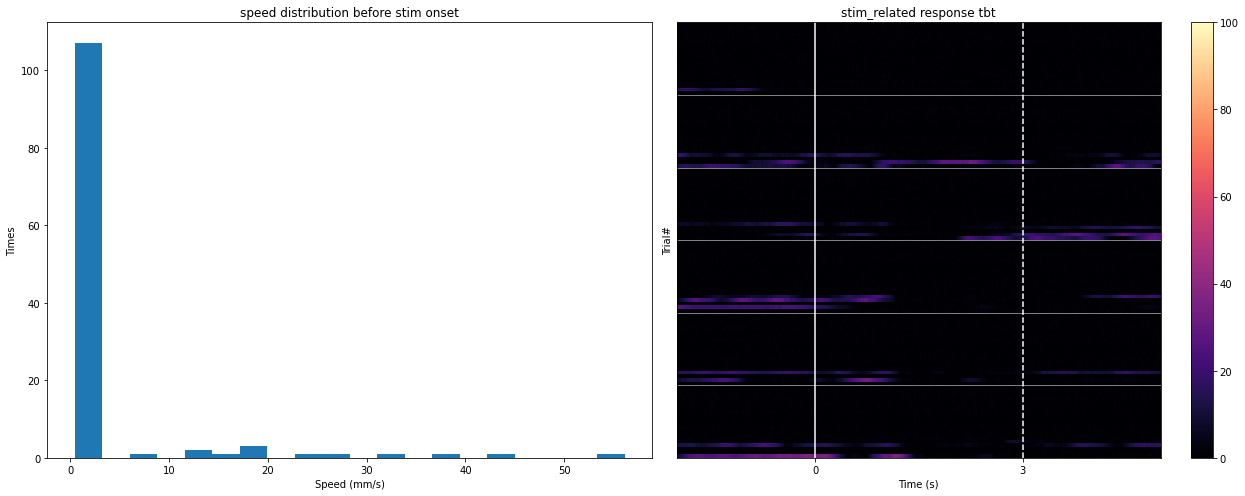

In [47]:
velocity_tbt, travel_distance_tbt =generate_preliminary_graph([data_list[0]])

In [49]:
velocity_tbt.shape

(120, 1007)

In [70]:
init_time=abs(analysis_window[0])

2

In [72]:
travel_distance_1sec_prior_stim=travel_distance_tbt[:,init_time*frame_rate,0]-travel_distance_tbt[:,(init_time-1)*frame_rate,0]
running_trial=travel_distance_1sec_prior_stim>5
running_velocity=velocity_tbt[running_trial,:]
travel_distance_1sec_post_stim=travel_distance_tbt[running_trial,(init_time+1)*frame_rate,0]-travel_distance_tbt[running_trial,init_time*frame_rate,0]
velocity_type1=running_velocity[travel_distance_1sec_post_stim>5,:]
velocity_type2=running_velocity[travel_distance_1sec_post_stim<5,:]

In [73]:
running_velocity=velocity_tbt[running_trial,:]

In [74]:
travel_distance_1sec_post_stim=travel_distance_tbt[running_trial,(init_time+1)*frame_rate,0]-travel_distance_tbt[running_trial,init_time*frame_rate,0]

In [78]:
velocity_type1=running_velocity[travel_distance_1sec_post_stim>5,:]
velocity_type2=running_velocity[travel_distance_1sec_post_stim<5,:]

In [80]:
velocity_type1.shape

(10, 1007)

(array([1., 1., 2., 1., 2., 2., 0., 0., 1., 1.]),
 array([ 3.5291033,  5.0336   ,  6.5380964,  8.042593 ,  9.54709  ,
        11.051586 , 12.556084 , 14.06058  , 15.565077 , 17.069572 ,
        18.57407  ], dtype=float32),
 <BarContainer object of 10 artists>)

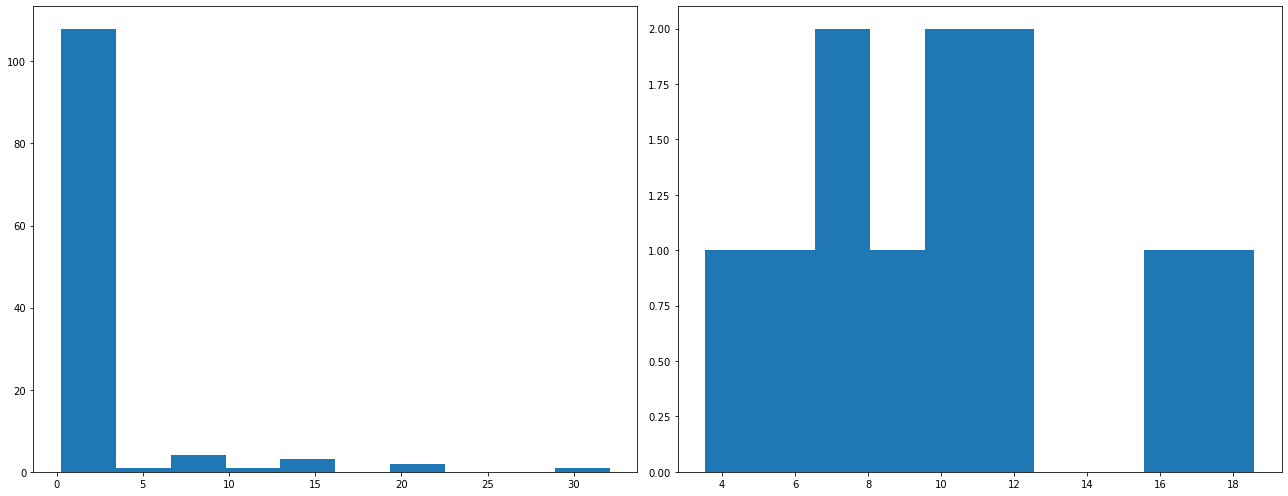

In [76]:
fig, (ax1,ax2)= plt.subplots(nrows=1, ncols=2, figsize=(18,7),tight_layout=True)
ax1.hist(travel_distance_1sec_prior_stim, bins=10)
ax2.hist(travel_distance_1sec_post_stim, bins=10)

In [54]:
analysis_window=[-2, 5]
frame_rate=144

In [56]:
velocity=velocity_type1

In [ ]:
import matplotlib as plt
import numpy as np
mean_velocity=np.mean(velocity, axis=0)
sem_velocity=np.std(velocity, axis=0, ddof=1) / np.sqrt(velocity.shape[0])
plot_file=f'stim_{stim_name_list[0]}_mean_velocity_from_{str(analysis_window[0])}_to_{str(analysis_window[1])}s.png'
mean_tile=np.mean(tp_tile, axis=0)
v_add_sem = mean_velocity + sem_velocity
v_min_sem = mean_velocity - sem_velocity
fig = plt.figure()
ax=fig.add_axes([0.1, 0.1, 0.8, 0.8]) # main axes
ax.plot(mean_tile,mean_velocity)
ax.fill_between(mean_tile,v_add_sem[:,0],v_min_sem[:,0], alpha=0.5, linewidth=0)
ax.axvline(x=abs(analysis_window[0]), color='black', linestyle='-', label='Stim start',linewidth=1)
ax.axvline(x=(abs(analysis_window[0])+stim_duration), color='black', linestyle='--', label='Stim end',linewidth=1)
plt.ylim(0, 60)
ax.set_yticks([0,30,60])
ax.set_yticklabels(['0','30','60'])
ax.set_xticks([0,2,4,6])
ax.set_xticklabels(['-2','0','2','4'])
# plt.savefig(thisDir+plot_file)

In [22]:
travel_distance_prior_stim=cum_travel_distance[:,init_time*frame_rate,0]

'Z:/DATA/experiment_trackball_Optomotor/L22122/221016/sweeploom'